# `ratio_study` - 04 Advanced diagnostics

Machine-learning inequity diagnostics (section 5) and sales-chasing detection (section 7).

| Notebook | Covers |
|---|---|
| [01 Basics](01_basics.ipynb) | Sections 1-2: indicators, confidence intervals, compliance checks, IQR trimming, charts, comparisons |
| [02 Spatial](02_spatial.ipynb) | Section 3: ratio maps, Moran's I, hot/cold spots, the VEM map |
| [03 Reporting](03_reporting.ipynb) | Section 4: PDF / XLSX / CSV / PNG output |
| [04 Advanced diagnostics](04_advanced_diagnostics.ipynb) | Sections 5 and 7: ML / SHAP inequity diagnostics and sales-chasing detection |
| [05 Vertical equity](05_vertical_equity.ipynb) | Section 6: VEI, the Vertical Equity Panel, VEM, the Gini family |

All five use the anonymised sample dataset bundled with the package - no data preparation required.
Section numbers are kept from the original single-notebook tour so cross-references still line up.

## Setup

Section 5 needs the ML extra; section 7 needs only the core install.

```
pip install "ratio_study[ml]"
```

In [1]:
# Uncomment on first run.
# %pip install "ratio_study[ml]"

In [2]:
import ratio_study as rs
import pandas as pd
import numpy as np
from pathlib import Path
from ratio_study import ml_diagnostics as ml       # section 5 - needs the [ml] extra

# inline plotting must be enabled AFTER importing ratio_study
%matplotlib inline

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

sample_df = rs.load_sample_dataset()

MARKET_VALUE = 'time_adjusted_sale_price'   # the market value proxy
ASSESSMENT   = 'assessment_value_new'       # the value under test (current CAMA model)
PRIOR_MODEL  = 'assessment_value_old'       # a previous model, for comparisons

sample_df['asr'] = sample_df[ASSESSMENT] / sample_df[MARKET_VALUE]   # ratio column, needed by the spatial and VE functions

results_directory = Path().resolve()   # outputs are written here
print('results will be written to:', results_directory)

print('ratio_study version:', rs.__version__)
print(f'{len(sample_df):,} sales, {sample_df.shape[1]} columns')

results will be written to: <path>ratio_study version: 0.4.5
12,583 sales, 20 columns


---
# 5. Machine learning for ratio analysis

Every indicator so far tests **one** hypothesis at a time: does the ratio move with price
(VEI, PRB), does it differ across neighbourhoods (grouped COD), is it spatially clustered
(Moran's I). Real inequity is often non-linear and interactive — a defect that only bites
for small bungalows in one part of town will pass all of those tests individually.

The idea, following **Bidanset & Wehrli** (GIS/Valuation Technologies 2025) and **Wehrli**
(IAAO/IPTI MAVS 2026), inverts the question:

> Fit a flexible model $\widehat{ASR} = F(X)$ on property characteristics.
> **If the ratio were equitable, $X$ should not predict it at all.**
> Whatever the model *can* predict is inequity, and SHAP says which characteristics carry it.

This is a natural extension of the Standard's instruction to check that valuation levels are
consistent across property characteristics before testing vertical equity — done for all
characteristics at once, and without assuming the relationship is linear.

Two design points worth understanding:

- **Sale price is deliberately excluded from $X$.** Since $ASR = AV/SP$, a model given $SP$
  need only reconstruct $AV$ from $X$ — which any competent CAMA model makes easy. The
  resulting R² would measure how well $X$ mimics the assessment model, not anything about
  equity. Price-related bias is the VEI's and PRB's job.
- **The R² is cross-fitted (out-of-fold).** An in-sample R² would be near 1 for any boosted
  tree, and would mean nothing. This is also the Standard's overfitting concern
  in a different guise.

Needs the ML extra: `pip install "ratio_study[ml]"`.

In [3]:
CHARACTERISTICS = ['living_area', 'lotsize', 'frontage', 'depth',
                   'quality_class', 'condition', 'baths', 'bedrooms',
                   'structure_type', 'property_type',
                   'neighbourhood', 'sale_month']

diag = ml.asr_predictability(sample_df,
                             market_value_header=MARKET_VALUE,
                             assessment_header=ASSESSMENT,
                             independent_variables=CHARACTERISTICS,
                             group_by='neighbourhood',
                             shap_sample_pct=0.20,
                             random_state=7)

print(f"Predictable share of the ASR (out-of-fold R2): {diag['predictability']:.1%}")
print(diag['attribution'])

Predictable share of the ASR (out-of-fold R2): 4.1%
Method: Bidanset & Wehrli, GIS/Valuation Technologies 2025; Wehrli, IAAO/IPTI MAVS 2026


## 5.1 How much? — the headline

`summary` states the result and how to read it. Low predictability is the good outcome: it
means the ratio looks like noise with respect to property characteristics, which is what
equity looks like.

In [4]:
diag['summary']

,Metric,Value,Reading
0,Predictable share of ASR (R²),0.041,the ratio looks close to noise w.r.t. these ch...
1,Unexplained share (1 - R²),0.959,variation no characteristic in X accounts for
2,Cross-fitting,3-fold out-of-fold,in-sample R² would be ~1 for any boosted tree
3,Target,asr (ASR units),sale price excluded as a feature by design


## 5.2 By what? — SHAP importance

Mean absolute SHAP per characteristic, ranked. Read a value as *"this characteristic moves
the ratio by about this much"*, in ratio points.

In [5]:
diag['shap_importance']

,feature,mean_abs_shap,share,mean_shap,rank
0,frontage,0.007552,0.142549,-0.000605,1
1,sale_month,0.007460,0.140820,0.000064,2
2,living_area,0.007186,0.135638,-0.000825,3
3,depth,0.007138,0.134737,0.000117,4
4,quality_class,0.005152,0.097247,-0.000050,5
5,lotsize,0.005126,0.096764,0.000022,6
6,neighbourhood,0.004938,0.093215,0.000105,7
7,property_type,0.002789,0.052652,0.000477,8
8,bedrooms,0.002289,0.043207,-0.000036,9
9,baths,0.001382,0.026081,0.000246,10


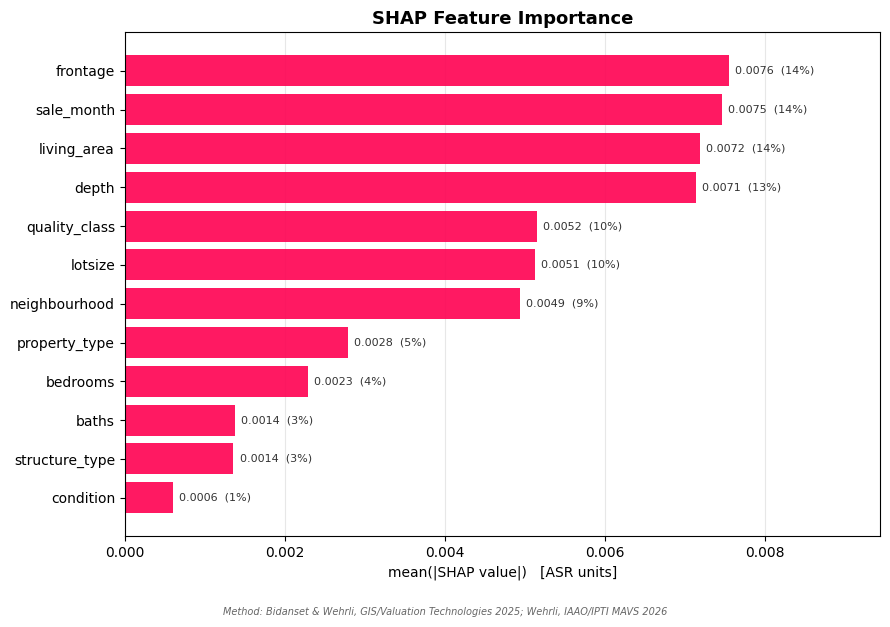

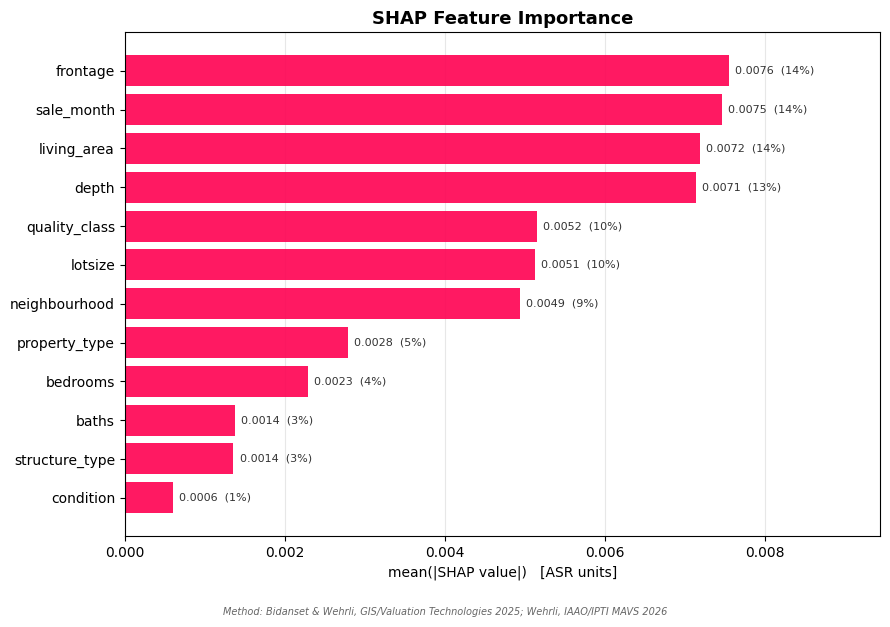

In [6]:
ml.shap_importance_plot(diag, top_n=12)

### The beeswarm: direction as well as magnitude

One dot per property per characteristic. Horizontal position is the SHAP value — how far
that characteristic pushed that property's ratio. Colour is the characteristic's own value.

A clean left-to-right colour gradient is the signature of systematic bias: *high values of
this characteristic consistently push the ratio one way*.

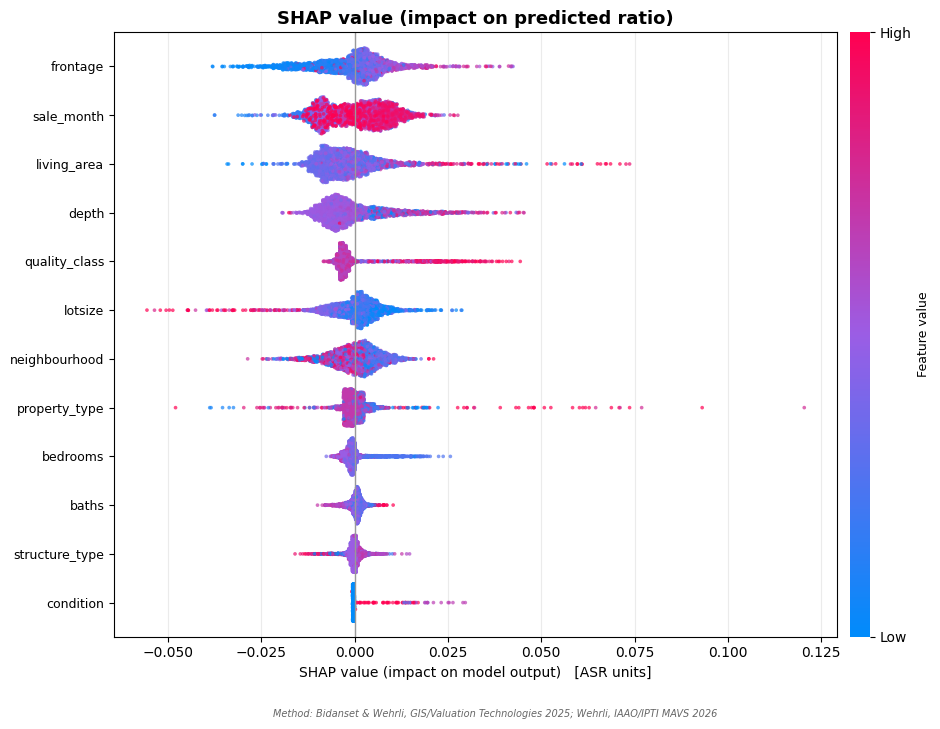

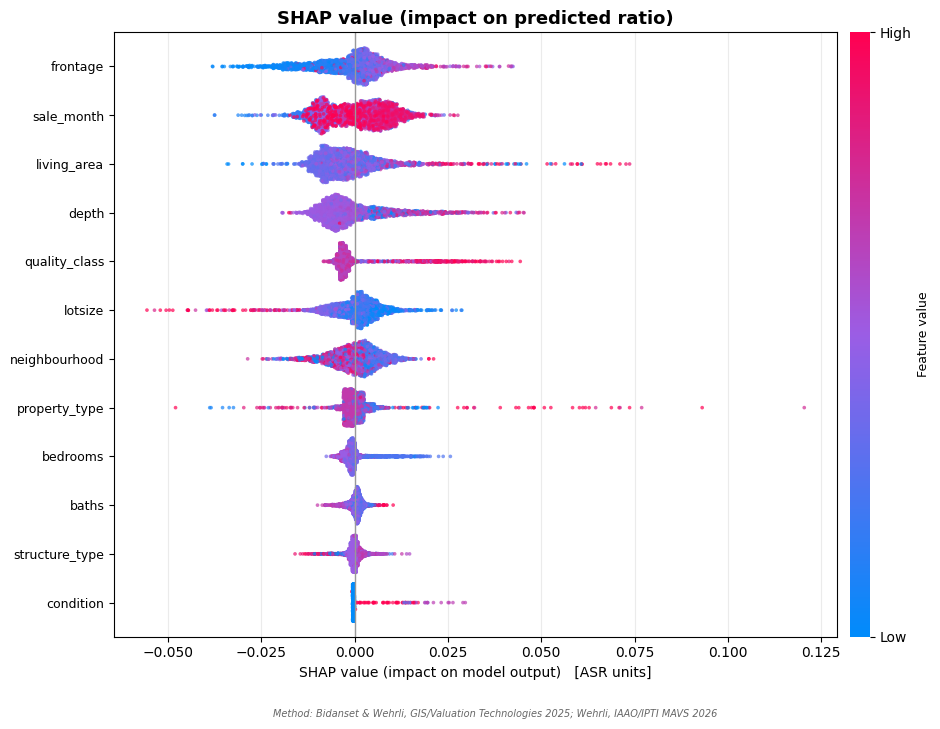

In [7]:
ml.shap_beeswarm_plot(diag, top_n=12)

### Dependence: the shape of one characteristic's effect

Plotting a characteristic's SHAP value against its own value exposes the non-linearity that
a PRB regression cannot see — thresholds, plateaus, and reversals. The Standard lists exactly
this as a PRB weakness: *"the method assumes a linear relationship … and its coefficient can
be misinterpreted should that not be the case."*

most influential characteristic: frontage


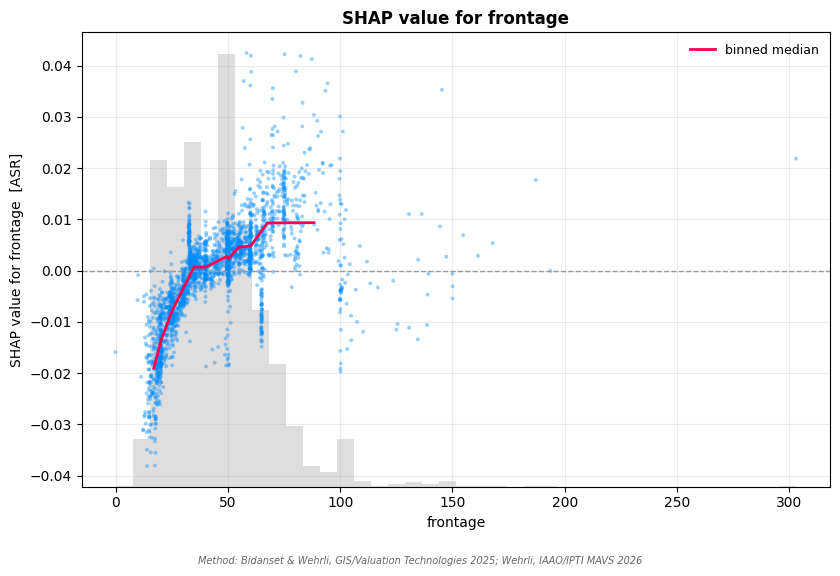

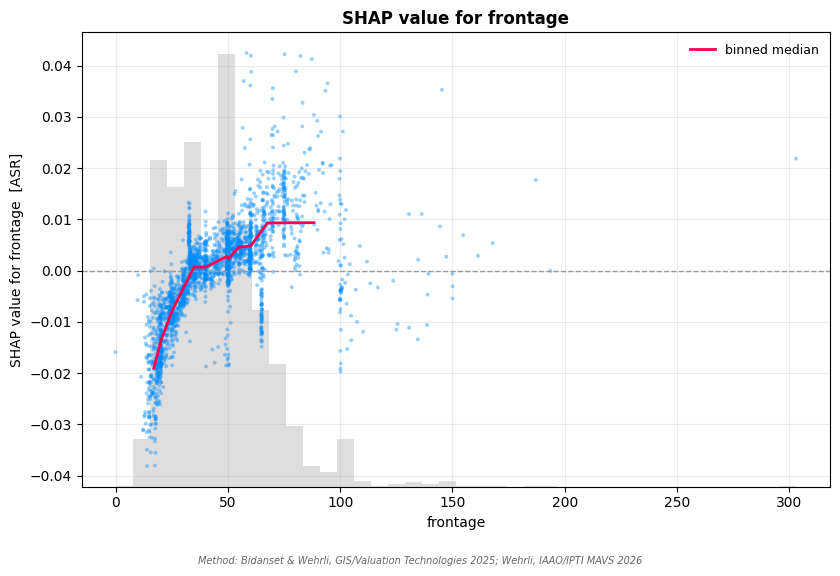

In [8]:
top_feature = diag['shap_importance'].iloc[0]['feature']
print('most influential characteristic:', top_feature)

ml.shap_dependence_plot(diag, feature=top_feature)

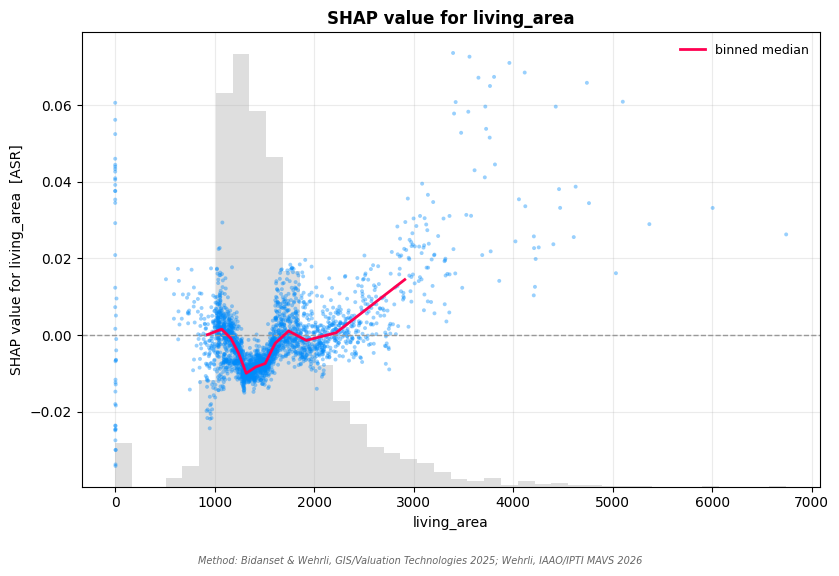

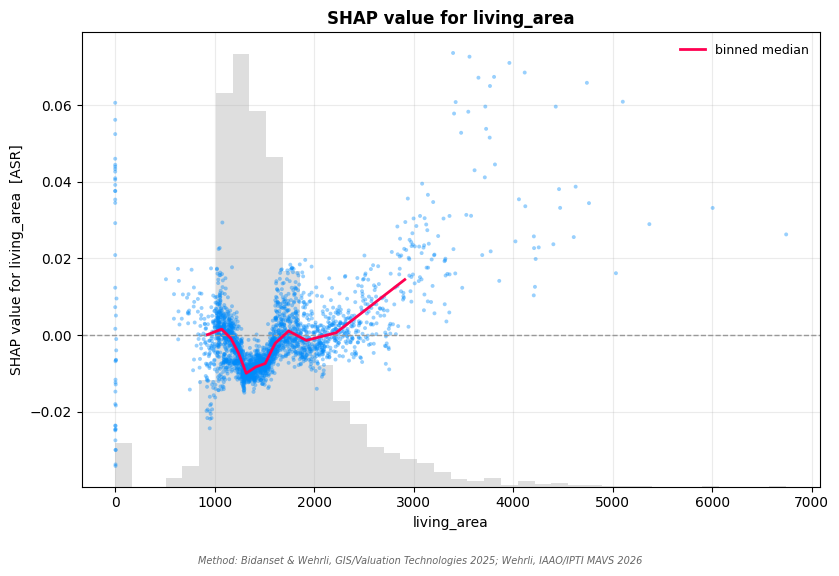

In [9]:
# Any characteristic can be interrogated the same way.
ml.shap_dependence_plot(diag, feature='living_area')

### Waterfall: one property, fully decomposed

For an appeal or a case review: this property's predicted ratio, broken into the
contribution of each characteristic, starting from the base rate.

> Remember — ratio study statistics do not judge an individual property. This chart
> explains the *model's* behaviour at one point, not that property's correct value.

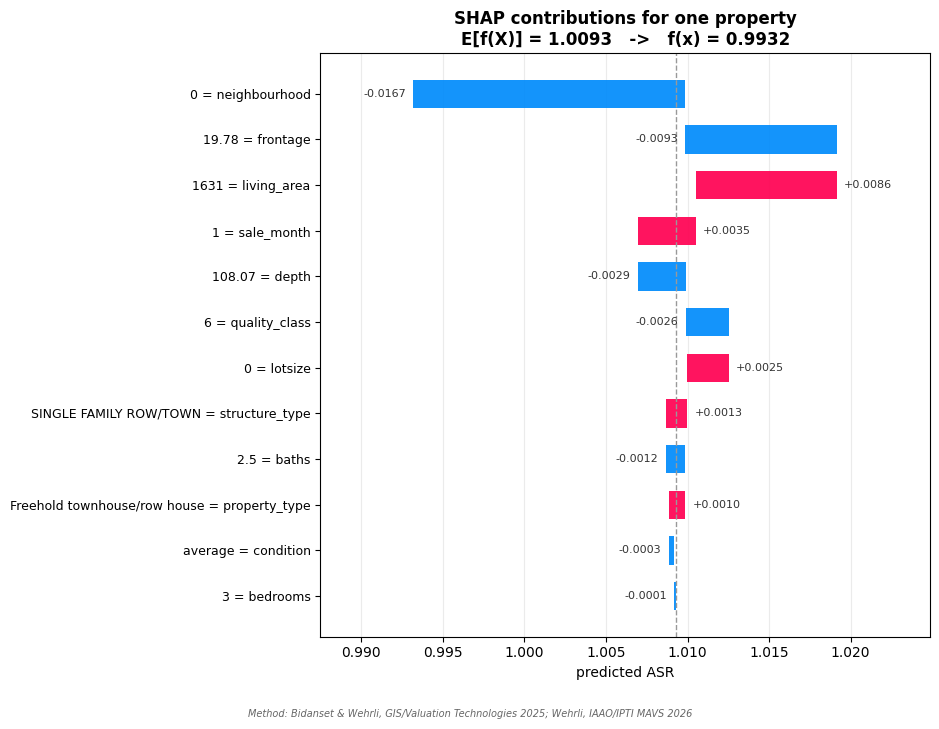

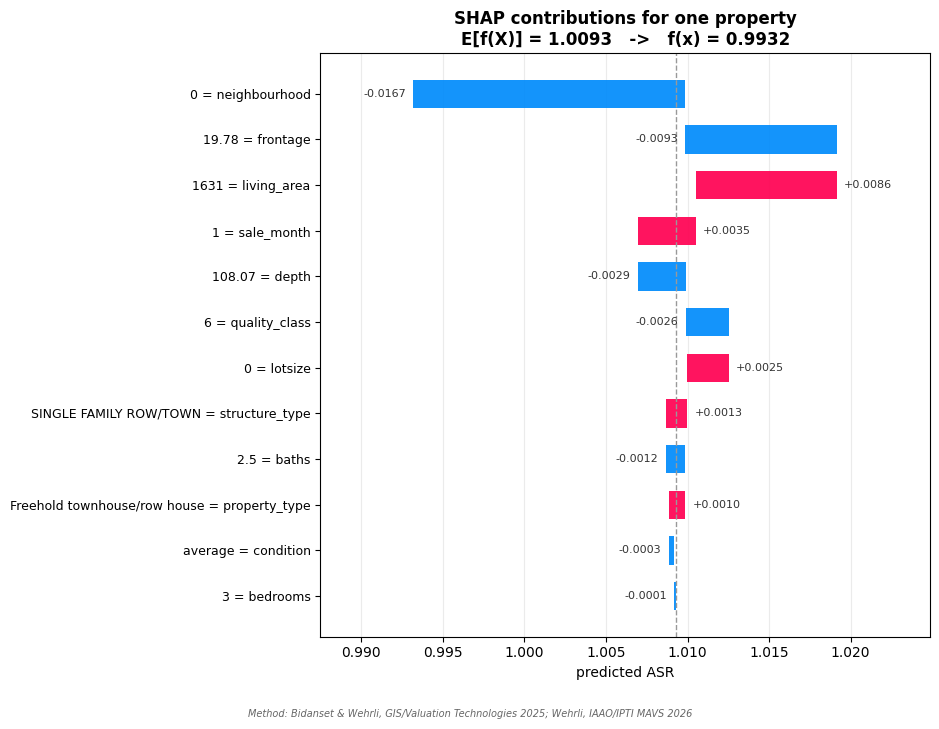

In [10]:
ml.shap_waterfall_plot(diag, row=0, top_n=12)

## 5.3 Subgroup diagnostics: CMBI and CDR

Two per-group statistics that pair with the grouped ratio tables from section 2.6:

- **CMBI** (Conditional Mean Bias Index) — how far a group's mean ratio sits from the
  overall mean. A *level* problem in that group — the Standard's five-percent test.
- **CDR** (Conditional Dispersion Ratio) — the group's ratio variance over the overall
  variance. Above 1 means the model is *less consistent* inside that group. A *uniformity*
  problem; the COD story.

Groups under `min_group_n` (30) are flagged unreliable rather than dropped, so a small
stratum never quietly disappears from the diagnosis.

In [11]:
cmbi_cdr = diag['cmbi_cdr']

print(f'{len(cmbi_cdr)} neighbourhoods assessed\n')
cmbi_cdr.head(15)

55 neighbourhoods assessed



,group,n,group_mean,cmbi,reliable,variance,cdr,flag
0,36,55,1.051576,0.042669,True,0.032242,1.946394,ok
1,29,256,0.979064,0.029843,True,0.004465,0.269547,ok
2,27,205,1.034614,0.025707,True,0.020850,1.258702,ok
3,51,45,1.027805,0.018898,True,0.067731,4.088839,ok
4,47,116,1.027576,0.018669,True,0.013719,0.828205,ok
5,50,103,0.990769,0.018138,True,0.007413,0.447514,ok
6,16,296,1.025791,0.016884,True,0.016702,1.008276,ok
7,19,438,1.025666,0.016759,True,0.018518,1.117873,ok
8,25,176,1.025177,0.016270,True,0.027904,1.684531,ok
9,0,84,0.994166,0.014741,True,0.016581,1.000982,ok


In [12]:
# Neighbourhoods that are both biased and inconsistent - the ones to look at first.
worst = cmbi_cdr[cmbi_cdr['reliable']].nlargest(10, 'cmbi')
(worst.style.format({'group_mean': '{:.4f}', 'cmbi': '{:.4f}',
                     'variance': '{:.5f}', 'cdr': '{:.3f}'})
      .background_gradient(subset=['cmbi', 'cdr'], cmap='Oranges')
      .set_caption('Largest conditional mean bias, reliable groups only'))

,group,n,group_mean,cmbi,reliable,variance,cdr,flag
0,36,55,1.0516,0.0427,True,0.03224,1.946,ok
1,29,256,0.9791,0.0298,True,0.00447,0.270,ok
2,27,205,1.0346,0.0257,True,0.02085,1.259,ok
3,51,45,1.0278,0.0189,True,0.06773,4.089,ok
4,47,116,1.0276,0.0187,True,0.01372,0.828,ok
5,50,103,0.9908,0.0181,True,0.00741,0.448,ok
6,16,296,1.0258,0.0169,True,0.01670,1.008,ok
7,19,438,1.0257,0.0168,True,0.01852,1.118,ok
8,25,176,1.0252,0.0163,True,0.02790,1.685,ok
9,0,84,0.9942,0.0147,True,0.01658,1.001,ok


## 5.4 Distance correlation

**Distance correlation** is zero *if and only if* two variables are independent — unlike
Pearson correlation, which is blind to non-linear dependence. Run per characteristic
against the ratio, it is a model-free screen: anything with a non-trivial `dcorr` is
related to the ratio somehow, whatever the shape of the relationship.

Useful as a cross-check on SHAP, since it makes no modelling assumptions at all.

In [13]:
diag['dcorr']

,variable,dcorr,flag
0,quality_class,0.102000,ok
1,condition,0.099264,ok
2,living_area,0.091157,ok
3,frontage,0.067868,ok
4,baths,0.065336,ok
5,property_type,0.064337,ok
6,depth,0.055971,ok
7,bedrooms,0.055322,ok
8,structure_type,0.054546,ok
9,lotsize,0.054054,ok


## 5.5 The whole diagnosis on one page

`asr_predictability_panel()` composites the answer — *how much*, then *by what* — into a
single figure suitable for a report or a slide. It is also what
`pdf_asr_predictability=True` embeds into a `ratios_report()` PDF.

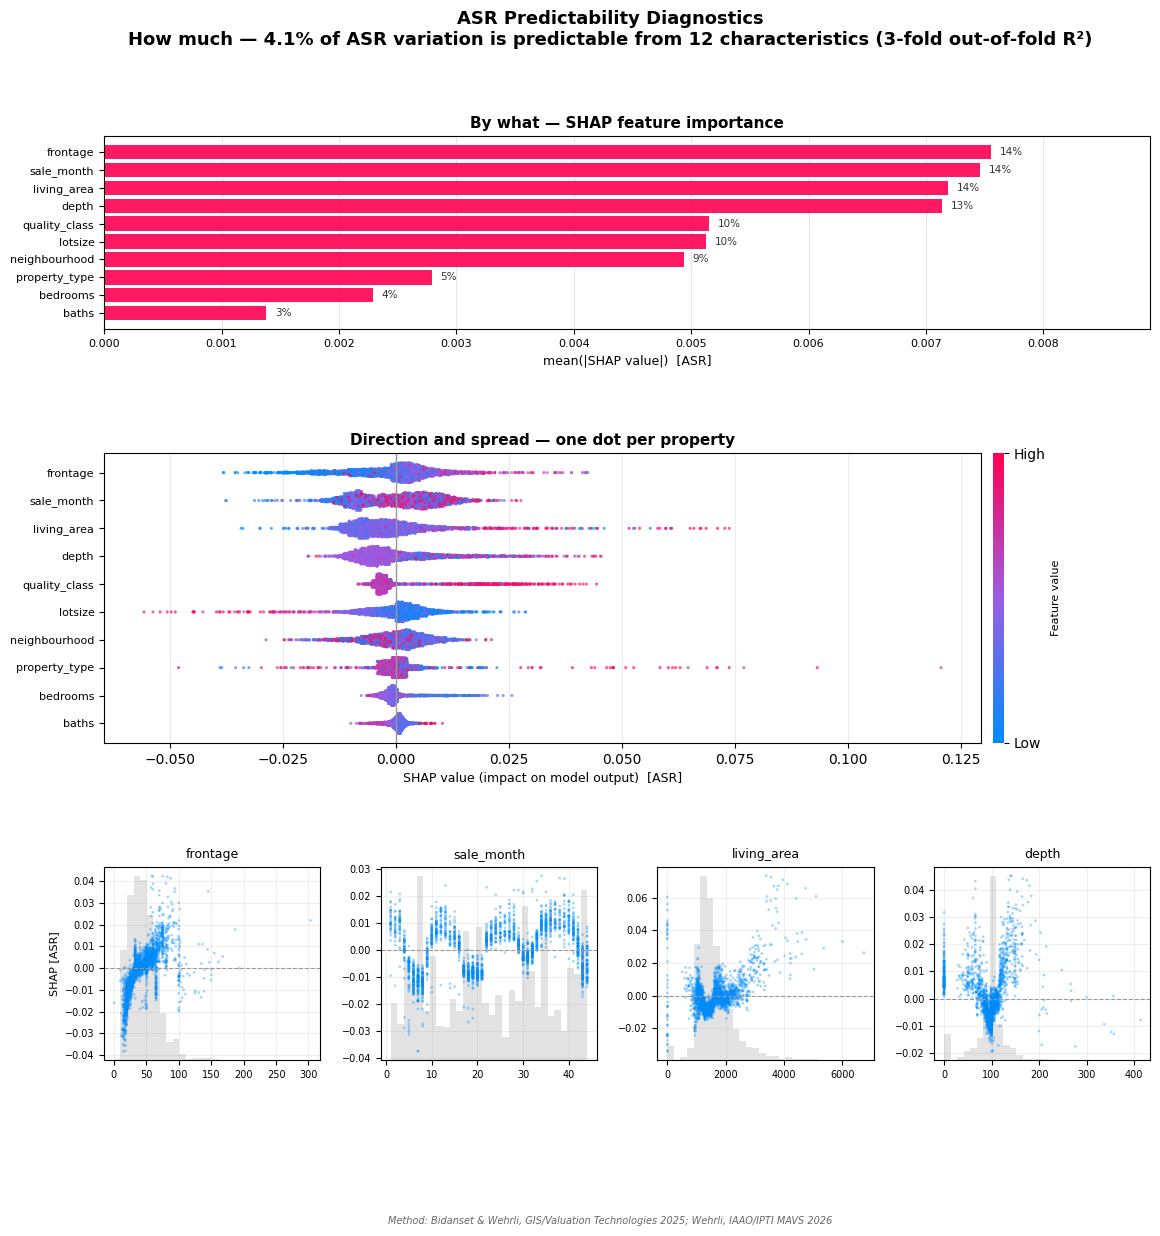

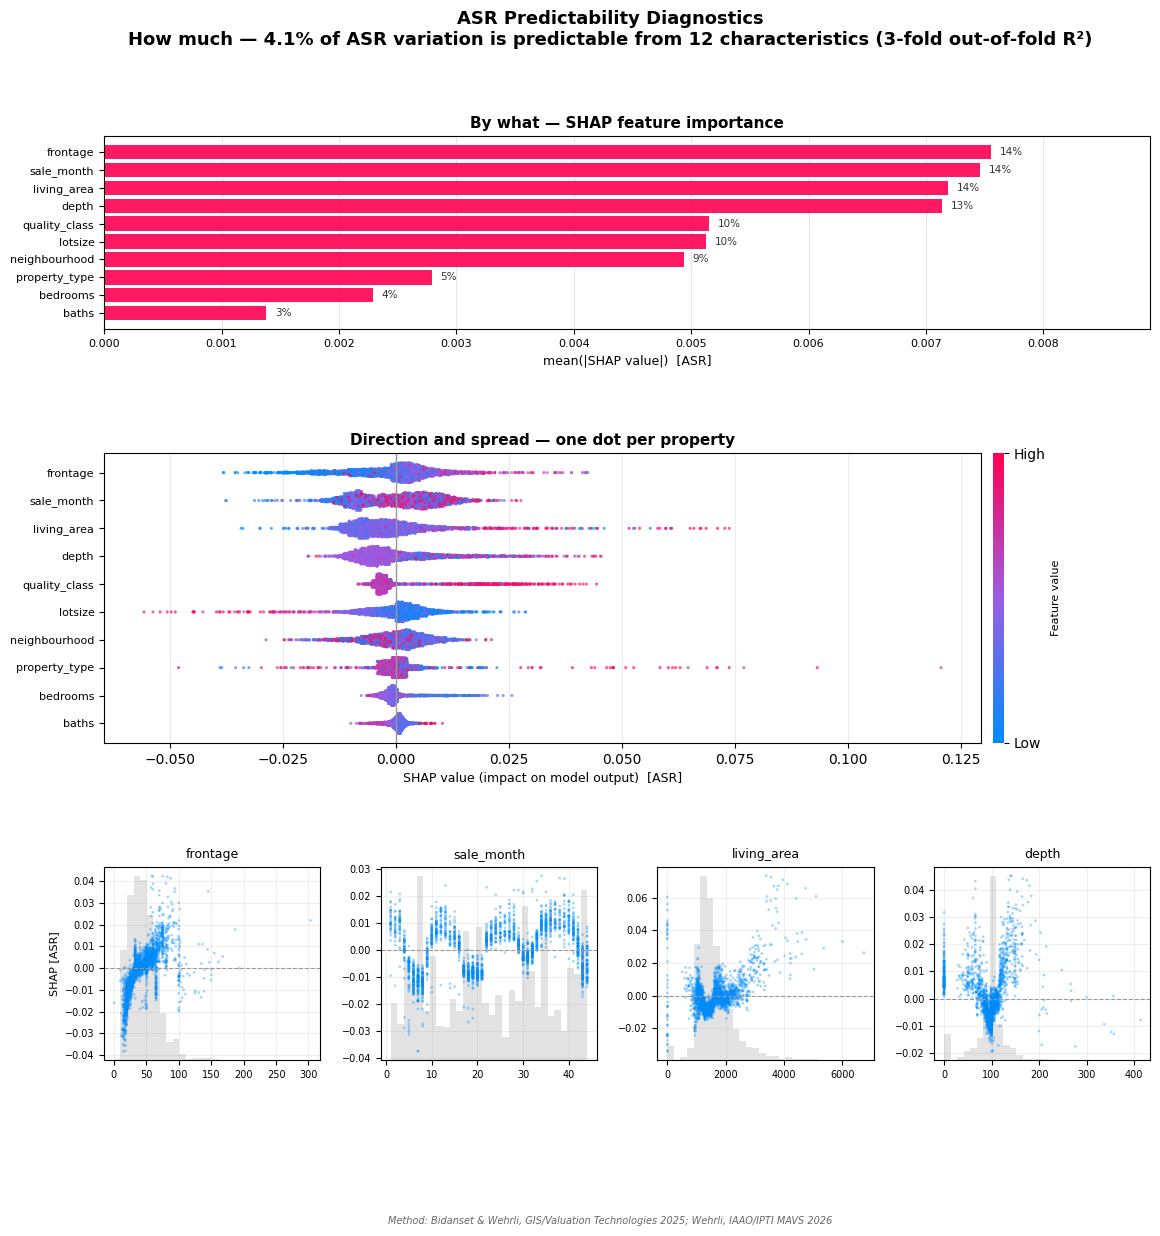

In [14]:
ml.asr_predictability_panel(diag, top_n=10, n_dependence=4)

### Wiring it into the report

The same diagnostics run inside `ratios_report()`, so an automated pipeline produces them
without a separate step.

In [15]:
ml_report = rs.ratios_report(
    sample_df,
    assessment_header=ASSESSMENT,
    market_value_header=MARKET_VALUE,
    group_by='property_type',
    descriptive=True,
    model_name='DemoModel_ML',
    export_directory=results_directory,
    export_in_compacted_file='',
    return_dict=False,
    pdf_args={'pdf_vertical_equity_panel': True,
              'pdf_asr_predictability': True,
              'asr_predictability_variables': CHARACTERISTICS,
              'asr_predictability_group_by': 'neighbourhood',
              'asr_predictability_shap_sample_pct': 0.20})

sorted(p.name for p in results_directory.glob('*DemoModelML*.pdf'))

Confidence interval settings  (<-- marks a value you set or is a default setting)
  Mode                  : distribution
  Level                 : 90%
  Indicators            : Median, Mean, Weighted_Mean, CoD, PRB, PRD
  Overall intervals     : on
  Per-group intervals   : off
  Minimum sales per row : 20
  Estimators            : Appendix D closed forms, plus PRB (regression) and PRD (delta method); bootstrap options ignored
VEI quantile method: R7


['ratio_study_DemoModelML_29sep2026_14h44.pdf',
 'ratio_study_DemoModelML_29sep2026_14h49.pdf']

---
# 7. Sales chasing detection

Everything in sections 2 to 6 rests on one assumption, and the Standard states it plainly: a ratio
study is valid *"to the extent that sold and unsold parcels are appraised at the same level
and in the same manner."*

**Sales chasing** — reappraising a property because it sold, at or near its selling price —
breaks that assumption. And it breaks it in the most dangerous possible direction: the
study looks *better*. Ratios cluster on 1.00, the COD falls, the level lands on target. The Standard
is blunt about the consequence: uniformity inferences *"will not be accurate (valuations
appear more uniform than they are)"* and measures of level *"will not be supportable"*.

This is why the Standard treats a **very low COD as a diagnostic warning** rather than a good
result, and why it devotes an entire section to detection. The package implements
it as a family:

| Function | What it needs | What it compares |
|---|---|---|
| `sc_value_change` | prior + current value, sold flag | Year-over-year value change, sold vs unsold |
| `sc_unit_values` | value, size, sold flag | Value per square foot, sold vs unsold |
| `sc_split_sample` | sale date + a cutoff | Sales the assessor could see vs could not |
| `sc_concentration` | ratios only | Share of ratios in a narrow band against the critical-concentration threshold |
| `sc_cdf_gap` | ratios only | A flat spot in the ratio CDF |
| `sc_mass_appraisal` | an independent model value | Assessment vs an independent estimate |
| `sc_independent_values` | an independent model value | The same, pointed at the oversight agency's own values |
| `detect_sales_chasing` | whatever you have | Runs everything the data supports |

The Standard asks valuers and oversight agencies to implement **at least one** of these.

## 7.1 Run everything the data supports

`detect_sales_chasing()` decides which tests it can run from the columns you pass, and
returns one tidy frame. The important design point: it reports the tests it **could not**
run, and why. "We did not test for it" and "we tested and found nothing" are different
findings, and an oversight agency reading the report has to be able to tell them apart.

In [16]:
SC_COLUMNS = ['technique', 'reference', 'n', 'statistic', 'threshold',
              'p_value', 'flag', 'conclusion']

screens = rs.detect_sales_chasing(df=sample_df,
                                  assessment_col=ASSESSMENT,
                                  sale_price_col=MARKET_VALUE)
screens[SC_COLUMNS]

,technique,reference,n,statistic,threshold,p_value,flag,conclusion
0,Ratio concentration,B.4,12583.0,0.149805,0.32,1.0,False,No evidence of sales chasing
1,CDF discontinuity,--,12583.0,0.000079,0.03,NaN,False,No evidence of sales chasing
2,"Value change, sold vs unsold",B.1,NaN,NaN,NaN,NaN,None,"not run: need `sold_col`, `prior_value_col`, `..."
3,"Unit value, sold vs unsold",B.2,NaN,NaN,NaN,NaN,None,"not run: need `sold_col`, `size_col`, `assessm..."
4,Split sample,B.3,NaN,NaN,NaN,NaN,None,not run: need `sale_date_col` and `cutoff_date`
5,Independent values,B.5 / B.6,NaN,NaN,NaN,NaN,None,"not run: need `independent_value_col`, `assess..."


With a sales file alone you get the two tests that need nothing else — the B.4
concentration screen and the CDF check. The other four report `not run` and name the column
that would enable them. Nothing here is flagged, which is the expected result for a model
whose sold and unsold parcels were valued the same way.

`group_by` runs the screens per stratum as well, because chasing is often a practice in one
office or one neighbourhood rather than jurisdiction-wide.

In [17]:
by_type = rs.detect_sales_chasing(df=sample_df,
                                  assessment_col=ASSESSMENT,
                                  sale_price_col=MARKET_VALUE,
                                  group_by='property_type')

flagged = by_type[by_type['flag'] == True]        # noqa: E712 - None is a third state
print(f'{len(by_type)} screens run across {by_type["scope"].nunique()} scopes; '
      f'{len(flagged)} flagged\n')
flagged[['technique', 'scope', 'n', 'statistic', 'threshold', 'conclusion']]

38 screens run across 17 scopes; 1 flagged



,technique,scope,n,statistic,threshold,conclusion
7,CDF discontinuity,Fiveplex,30.0,0.033333,0.03,Sales chasing indicated: 1 of 30 sales (3.3%) ...


> *"Even when critical proportions of ratios are
> exceeded, further investigation should be conducted before concluding that sales chasing
> has occurred."* A flag is a prompt to look, not a verdict — and on a small stratum a
> single duplicated ratio can trip the CDF screen.

## 7.2 What detection looks like when there *is* something to find

The honest way to demonstrate a detector is to give it something to detect. Here is the
same sales file with 30% of the sales reassessed to their own sale price — the textbook
chase.

In [18]:
rng = np.random.default_rng(7)
chased = sample_df.copy()
hit = rng.choice(chased.index, size=int(len(chased) * 0.30), replace=False)
chased.loc[hit, ASSESSMENT] = chased.loc[hit, MARKET_VALUE] * rng.normal(1.0, 0.004, len(hit))

# The study now looks *better* - which is exactly the problem.
comparison = pd.DataFrame({
    'clean':  rs.ratios(sample_df, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
                        indicators=['Median', 'CoD', 'PRD'], print_ci_settings=False).iloc[0],
    'chased': rs.ratios(chased, assessment_header=ASSESSMENT, market_value_header=MARKET_VALUE,
                        indicators=['Median', 'CoD', 'PRD'], print_ci_settings=False).iloc[0],
})
comparison.loc[['Count', 'Median', 'CoD', 'PRD']]

,clean,chased
Count,"12,583","12,583"
Median,0.9985,0.9998
CoD,9.48%,6.71%
PRD,1.0120,1.0085


The COD drops sharply and the median moves onto 1.00. Judged on the compliance table alone
this is the better model. It is not — it is the same model with a third of its evidence
contaminated.

Now the screens:

In [19]:
rs.detect_sales_chasing(df=chased,
                        assessment_col=ASSESSMENT,
                        sale_price_col=MARKET_VALUE)[SC_COLUMNS]

,technique,reference,n,statistic,threshold,p_value,flag,conclusion
0,Ratio concentration,B.4,12583.0,0.404355,0.32,6.886747e-109,True,Sales chasing indicated
1,CDF discontinuity,--,12583.0,0.000079,0.03,NaN,False,No evidence of sales chasing
2,"Value change, sold vs unsold",B.1,NaN,NaN,NaN,NaN,None,"not run: need `sold_col`, `prior_value_col`, `..."
3,"Unit value, sold vs unsold",B.2,NaN,NaN,NaN,NaN,None,"not run: need `sold_col`, `size_col`, `assessm..."
4,Split sample,B.3,NaN,NaN,NaN,NaN,None,not run: need `sale_date_col` and `cutoff_date`
5,Independent values,B.5 / B.6,NaN,NaN,NaN,NaN,None,"not run: need `independent_value_col`, `assess..."


The concentration test catches it decisively: 40% of ratios fall within ±2% of the median, against the 32%
the Standard says is the most a genuine sample with a 4% COD should produce.

`critical_concentration()` is that table, callable. Given the lowest COD credibly achievable
for a property type, it returns the share of ratios above which chasing is the likely
explanation.

In [20]:
cods = (0.016, 0.04, 0.05, 0.06, 0.08, 0.10)
table = pd.DataFrame([rs.critical_concentration(min_achievable_cod=c) for c in cods],
                     index=[f'{c:.1%}' for c in cods])
table.index.name = 'minimum achievable COD'
table.rename(columns={'sd': 'implied SD',
                      'expected_proportion': 'expected share within ±2%',
                      'critical_proportion': 'critical share'})

,implied SD,expected share within ±2%,critical share
minimum achievable COD,,,
1.6%,0.0200,0.682689,0.69
4.0%,0.0500,0.310843,0.32
5.0%,0.0625,0.251032,0.26
6.0%,0.0750,0.210274,0.22
8.0%,0.1000,0.158519,0.16
10.0%,0.1250,0.127119,0.13


## 7.3 The roll-based tests

B.1 and B.2 are the tests that speak to the mechanism rather than a symptom, and they need
the **unsold** population — which an assessor has and an oversight agency usually does not.

The sample file is sales only, so the cell below builds a synthetic roll: a sold flag, a
prior value, and a current value in which the unsold were not revalued at all while the
sold were set to their sale price.

In [21]:
roll = sample_df.copy()
roll['sold'] = False
roll.loc[np.random.default_rng(3).choice(roll.index, 3000, replace=False), 'sold'] = True

roll['prior_value'] = roll[PRIOR_MODEL]
roll['current_value'] = roll[PRIOR_MODEL]                       # unsold: no revaluation
roll.loc[roll['sold'], 'current_value'] = roll.loc[roll['sold'], MARKET_VALUE]   # sold: chased

b1 = rs.sc_value_change(roll, sold_col='sold',
                        prior_value_col='prior_value', current_value_col='current_value')
pd.Series({k: v for k, v in b1.items() if k != 'detail'}).to_frame('B.1 value change')

,B.1 value change
n_sold,3000
n_unsold,9583
n_excluded,0
sold_pct_no_change,0.0
unsold_pct_no_change,1.0
statistic,mean
sold_statistic,0.077535
unsold_statistic,0.0
difference,0.077535
tolerance,0.05


Two refinements are visible in that output:

- **`statistic` switched to `mean`.** The Standard prefers the median, but notes that *"if this
  proportion is high in the unsold group, the median value change in that group may not be
  meaningful, in which case the mean should be used."* Here `unsold_pct_no_change` is 100%,
  so the median change is 0 for everyone and carries no information. The function noticed.
- **`statistically_significant` and `practically_significant` are reported separately.**
  The Standard warns that on large samples *"small differences … can be proven to be statistically
  significant, yet the actual differences may be slight"*, and sets a 5% tolerance on top of
  the p-value. Both must clear before anything is flagged.

The unit-value test needs only one year of values plus a size column, which is often the difference between
a test you can run and one you cannot.

In [22]:
b2 = rs.sc_unit_values(roll, sold_col='sold',
                       value_col='current_value', size_col='living_area')
pd.Series({k: v for k, v in b2.items() if k != 'detail'}).to_frame('B.2 unit values')

,B.2 unit values
n_sold,2981
n_unsold,9515
n_excluded,0
statistic,median
sold_statistic,1.064214
unsold_statistic,1.0
difference,0.064214
tolerance,0.05
mannwhitney_p,0.0
ttest_p,0.428083


## 7.4 The split-sample test

B.3 is the one technique an oversight agency can run on a sales file alone. It splits the
sales at the last date the assessor could have acted on them: sales *before* the cutoff
could have been chased, sales *after* it could not. Adjusted for time, the two halves should
agree.

The sample file carries `sale_month` rather than a date, so the cell builds one.

In [23]:
dated = sample_df.assign(
    sale_date=pd.to_datetime('2022-01-01')
              + pd.to_timedelta((sample_df['sale_month'] - 1) * 30, unit='D'))

b3 = rs.sc_split_sample(dated,
                        assessment_col=ASSESSMENT,
                        sale_price_col=MARKET_VALUE,
                        sale_date_col='sale_date',
                        cutoff_date='2023-10-01')     # last date values could change

pd.Series({k: v for k, v in b3.items() if k != 'detail'}).to_frame('B.3 split sample')

,B.3 split sample
cutoff_date,2023-10-01
n_known,6473
n_unknown,6110
median_known,0.994181
median_unknown,1.00247
cod_known,0.093426
cod_unknown,0.096201
median_ci_known,"(0.9912116452098764, 0.9973966205633202)"
median_ci_unknown,"(0.9995516257262528, 1.0053295103302382)"
cod_ci_known,"(0.09135465915717883, 0.09553447221081926)"


The verdict is *Inconclusive*, and the wording is worth reading: the two subsamples do
differ significantly, but no statistic is **both** better in the could-have-been-chased half
**and** outside its tolerance. Chasing makes the earlier half look *better*; a difference
that is merely present, or that runs the wrong way, is not evidence of it.

## 7.5 Where this belongs in a study

Run a screen every cycle, not only when something looks wrong — the whole hazard is that
chasing makes a study look right. In practice:

1. **Before trusting a low COD.** The Standard treats a COD below the range as a
   warning sign; a concentration screen is the cheapest way to check it.
2. **Before publishing.** The Standard asks the report to describe methodology and the proper use of
   results. A line recording which screens ran and what they found belongs there.
3. **Whenever the sample was not built by you.** The Standard lists the influence of sales
   chasing as *"difficult to detect or prevent"* among the disadvantages of using
   assessor-supplied sales.

And if a screen does flag, the Standard sets out the remedy: redo the study on a sample period
that precludes chasing — typically sales occurring *after* the last date values could be
changed, time-adjusted back to the valuation date — before any reappraisal or equalization
decision is taken.

---
**Next:** [05 Vertical equity](05_vertical_equity.ipynb).